In [1]:
#from zcb_pricer import *
from mkt_yc_generator import *
from vasicek_calibrator import vasicek_calibrator
import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

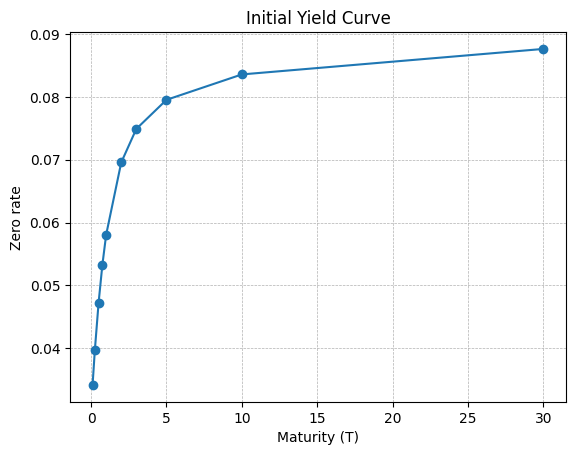

In [2]:
#====================================================
# Example initial market yield curve data
#====================================================
T_mkt = np.array([0.1, 0.25, 0.5, 0.75, 1, 2, 3, 5, 10, 30])
y_mkt = yield_curve(T_mkt)
price_mkt = np.exp(-y_mkt * T_mkt)  # Convert yields to prices

plt.figure()
plt.plot(T_mkt, y_mkt, marker='o')
plt.xlabel("Maturity (T)")
plt.ylabel("Zero rate")
plt.title("Initial Yield Curve")
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()

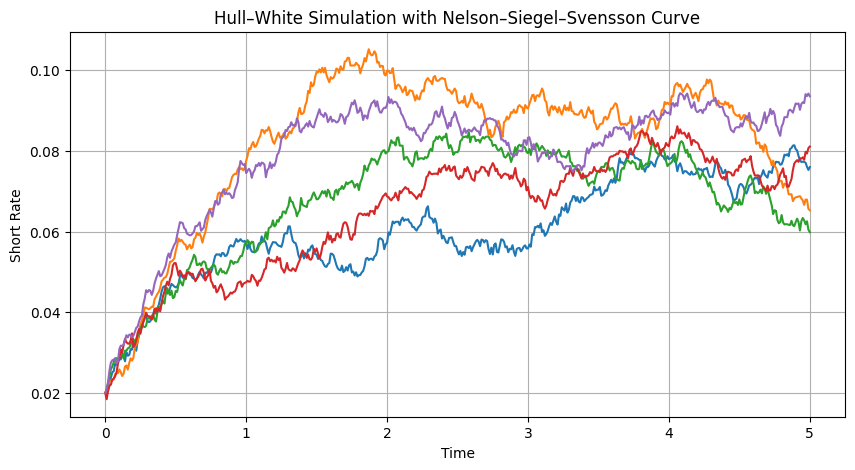

In [4]:
# -----------------------------
# Discount factor
# -----------------------------
def P0(T):
    y = yield_curve(T)
    return np.exp(-y * T)

# -----------------------------
# Forward rate (numerical, robust)
# -----------------------------
def f0(T, eps=1e-5):
    return -(np.log(P0(T + eps)) - np.log(P0(T - eps))) / (2 * eps)

def df0(T, eps=1e-5):
    return (f0(T + eps) - f0(T - eps)) / (2 * eps)

# -----------------------------
# Hull–White parameters
# -----------------------------
a = 0.15
sigma = 0.01
r0 = 0.02

T_end = 5.0
N = 500
dt = T_end / N
M = 10

t_grid = np.linspace(0, T_end, N + 1)

# -----------------------------
# theta(t)
# -----------------------------
def theta(t):
    f = f0(t)
    df = df0(t)
    return df + a * f + (sigma**2 / (2 * a)) * (1 - np.exp(-2 * a * t))

# -----------------------------
# Exact Hull–White simulation
# -----------------------------
def simulate_hw():
    r = np.zeros((M, N + 1))
    r[:, 0] = r0

    exp_at = np.exp(-a * dt)
    var = sigma**2 * (1 - np.exp(-2 * a * dt)) / (2 * a)
    std = np.sqrt(var)

    for i in range(N):
        t = t_grid[i]
        z = np.random.normal(size=M)

        th = theta(t)

        r[:, i + 1] = (
            r[:, i] * exp_at
            + th * (1 - exp_at) / a
            + std * z
        )

    return r

# -----------------------------
# Run
# -----------------------------
paths = simulate_hw()

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(10, 5))
for i in range(min(5, M)):
    plt.plot(t_grid, paths[i])

plt.title("Hull–White Simulation with Nelson–Siegel–Svensson Curve")
plt.xlabel("Time")
plt.ylabel("Short Rate")
plt.grid(True)
plt.show()